In [22]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# PARAMETERS & HSV TUNING RANGES
# ==============================================================================
SHOW_PREVIEW = True  # Set to True to display processing preview per frame

# HSV ranges (Hue: 0-180, Saturation: 0-255, Value: 0-255)
# Fine-tune these bounds if lighting varies
LOWER_YELLOW = np.array([15, 170, 170])
UPPER_YELLOW = np.array([35, 255, 255])

LOWER_GREEN = np.array([35, 50, 50])
UPPER_GREEN = np.array([85, 255, 255])

# Minimum radius to filter out noise (in pixels)
MIN_PHANTOM_RADIUS = 30


# ==============================================================================
# VIDEO PROCESSING LOOP
# ==============================================================================
def analyze_phantom_rotation(video_path):
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise FileNotFoundError(f"Could not open video file: {video_path}")

    fps = cap.get(cv2.CAP_PROP_FPS)
    if fps == 0 or np.isnan(fps):
        fps = 60.0  # Default fallback if video metadata lacks FPS

    frame_idx = 0

    # Data arrays
    times = []
    center_positions = []  # (x, y)
    radii = []  # r
    sticker_positions = []  # (x, y)
    angles_deg = []  # raw angle in degrees [-180, 180]

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        current_time = frame_idx / fps
        hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

        # ----------------------------------------------------------------------
        # 1. Detect Yellow Phantom Circle
        # ----------------------------------------------------------------------
        yellow_mask = cv2.inRange(hsv, LOWER_YELLOW, UPPER_YELLOW)
        yellow_mask = cv2.morphologyEx(
            yellow_mask, cv2.MORPH_OPEN, kernel, iterations=2
        )
        yellow_mask = cv2.morphologyEx(
            yellow_mask, cv2.MORPH_CLOSE, kernel, iterations=2
        )

        contours_yellow, _ = cv2.findContours(
            yellow_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )

        center_x, center_y, radius = np.nan, np.nan, np.nan
        sticker_x, sticker_y = np.nan, np.nan
        angle = np.nan

        if contours_yellow:
            # Assume largest yellow region is the phantom
            largest_contour = max(contours_yellow, key=cv2.contourArea)
            (cx, cy), r = cv2.minEnclosingCircle(largest_contour)

            if r >= MIN_PHANTOM_RADIUS:
                center_x, center_y, radius = float(cx), float(cy), float(r)

                # --------------------------------------------------------------
                # 2. Detect Green Sticker within Phantom Region
                # --------------------------------------------------------------
                # Mask out everything outside the detected circle
                circle_mask = np.zeros(
                    frame.shape[:2], dtype=np.uint8
                )
                cv2.circle(
                    circle_mask,
                    (int(center_x), int(center_y)),
                    int(radius),
                    255,
                    -1,
                )

                green_mask = cv2.inRange(hsv, LOWER_GREEN, UPPER_GREEN)
                green_inside_phantom = cv2.bitwise_and(
                    green_mask, green_mask, mask=circle_mask
                )
                green_inside_phantom = cv2.morphologyEx(
                    green_inside_phantom, cv2.MORPH_OPEN, kernel
                )

                # Calculate centroid of green pixels inside circle
                green_pts = cv2.findNonZero(green_inside_phantom)
                if green_pts is not None:
                    sticker_x = float(np.mean(green_pts[:, 0]))
                    sticker_y = float(np.mean(green_pts[:, 1]))

                    # ----------------------------------------------------------
                    # 3. Calculate Rotation Angle
                    # ----------------------------------------------------------
                    # Standard cartesian angle: Y inverted because image origin is top-left
                    dx = sticker_x - center_x
                    dy = -(
                        sticker_y - center_y
                    )  # Invert Y so 90 deg points straight up
                    angle = np.degrees(np.arctan2(dy, dx))

        # Store tracked data
        times.append(current_time)
        center_positions.append((center_x, center_y))
        radii.append(radius)
        sticker_positions.append((sticker_x, sticker_y))
        angles_deg.append(angle)

        # ----------------------------------------------------------------------
        # Optional Visual Feedback Overlay
        # ----------------------------------------------------------------------
        if SHOW_PREVIEW and not np.isnan(center_x):
            annotated = frame.copy()
            cv2.circle(
                annotated,
                (int(center_x), int(center_y)),
                int(radius),
                (255, 0, 0),
                2,
            )
            cv2.circle(
                annotated,
                (int(center_x), int(center_y)),
                4,
                (0, 0, 255),
                -1,
            )

            if not np.isnan(sticker_x):
                cv2.circle(
                    annotated,
                    (int(sticker_x), int(sticker_y)),
                    5,
                    (0, 255, 0),
                    -1,
                )
                cv2.line(
                    annotated,
                    (int(center_x), int(center_y)),
                    (int(sticker_x), int(sticker_y)),
                    (0, 255, 255),
                    2,
                )

            cv2.putText(
                annotated,
                f"Angle: {angle:.1f} deg",
                (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.8,
                (0, 255, 255),
                2,
            )
            cv2.imshow("Phantom Tracking", cv2.resize(annotated, (800, 450)))

            if cv2.waitKey(1) & 0xFF == ord("q"):
                break

        frame_idx += 1

    cap.release()
    cv2.destroyAllWindows()

    # Convert output lists to numpy arrays
    times = np.array(times)
    center_positions = np.array(center_positions)
    radii = np.array(radii)
    sticker_positions = np.array(sticker_positions)
    angles_deg = np.array(angles_deg)

    # Calculate continuous unwrapped angle (prevents -180 to +180 deg jumps)
    valid_mask = ~np.isnan(angles_deg)
    angles_unwrapped = np.copy(angles_deg)
    if np.any(valid_mask):
        angles_unwrapped[valid_mask] = np.degrees(
            np.unwrap(np.radians(angles_deg[valid_mask]))
        )

    return {
        "time": times,
        "center_pos": center_positions,
        "radius": radii,
        "sticker_pos": sticker_positions,
        "angle_deg": angles_deg,
        "angle_unwrapped_deg": angles_unwrapped,
    }

datas = []
videos = ["tamas.mp4","sajat.mp4"]

for video in videos:
    data = analyze_phantom_rotation(video)
    datas.append(data)


QFontDatabase: Cannot find font directory /home/sz/Arduino/git_folder/DynamicMriPhantom/python_serial/.venv/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/sz/Arduino/git_folder/DynamicMriPhantom/python_serial/.venv/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/sz/Arduino/git_folder/DynamicMriPhantom/python_serial/.venv/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/sz/Arduino/git_folder/DynamicMriPhantom/python_serial/.venv/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer s

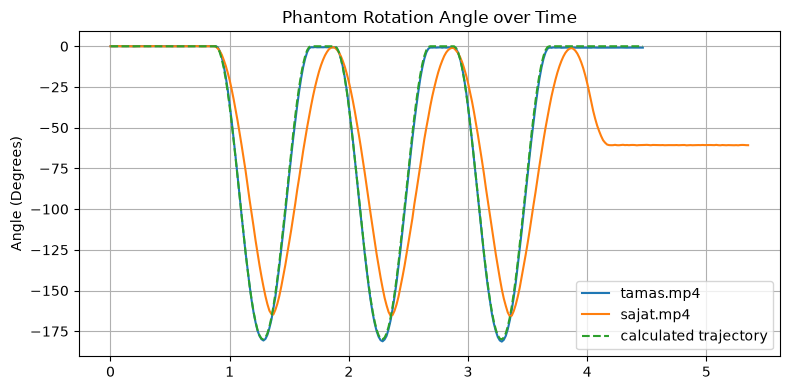

In [18]:
# ==============================================================================
# DISPLAY & PLOTTING RESULTS
# ==============================================================================
def plot_results(data):
    time = data["time"]
    angles_raw = data["angle_deg"]
    angles_unwrapped = data["angle_unwrapped_deg"] - data["angle_unwrapped_deg"][0]
    centers = data["center_pos"] - data["center_pos"][0]

    fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)

    # 1. Raw Angle vs Continuous Unwrapped Angle
    #axes[0].plot(
    #    time, angles_raw, label="Raw Angle (-180 to 180°)", alpha=0.5
    #)
    axes[0].plot(
        time,
        angles_unwrapped,
        label="Continuous Unwrapped Angle",
        color="crimson",
    )
    axes[0].set_ylabel("Angle (Degrees)")
    axes[0].set_title("Phantom Rotation Angle over Time")
    axes[0].legend()
    axes[0].grid(True)

    # 2. Center Position Drift (X and Y)
    axes[1].plot(time, centers[:, 0], label="Center X", color="blue")
    axes[1].plot(time, centers[:, 1], label="Center Y", color="orange")
    axes[1].set_ylabel("Position (Pixels)")
    axes[1].set_title("Phantom Center Motion (Wobble/Drift)")
    axes[1].legend()
    axes[1].grid(True)

    # 3. Angular Velocity (dTheta / dt)
    dt = np.diff(time, prepend=time[1] - time[0])
    angular_velocity = (
        np.gradient(angles_unwrapped, time) / 360.0
    ) * 60.0  # RPM
    axes[2].plot(time, angular_velocity, color="green")
    axes[2].set_ylabel("Speed (RPM)")
    axes[2].set_xlabel("Time (Seconds)")
    axes[2].set_title("Phantom Angular Velocity (RPM)")
    axes[2].grid(True)

    plt.tight_layout()
    plt.show()

def plot_multiple_results(datas,videos):

    fig, ax = plt.subplots(1, 1, figsize=(8, 4), sharex=True)

    for i in range(len(datas)):
        data = datas[i]
        time = data["time"]
        angles_unwrapped = data["angle_unwrapped_deg"] - data["angle_unwrapped_deg"][0]

        ax.plot(
            time,
            angles_unwrapped,
            label=videos[i],
    )

    time = datas[0]["time"]
    angles_calculated = generate_trajectory(time)
    
    ax.plot(
            time,
            angles_calculated,
            label="calculated trajectory",
            linestyle = '--',
    )

    ax.set_ylabel("Angle (Degrees)")
    ax.set_title("Phantom Rotation Angle over Time")
    ax.legend()
    ax.grid(True)

    plt.tight_layout()
    plt.show()

def generate_trajectory(times, move_time = 800, dwell_time = 200, amplitude = 180, gamma = 0):

    period_num = 3
    cycles_start = 880

    times = times*1000 - cycles_start


    full_period_ms = move_time + dwell_time

    positions = []

    for time in times:

        if(time < 0 or time > period_num * full_period_ms): #before and after the movement
            position = 0
        else:
            time = time % full_period_ms

        if(time > 0 and time < move_time): #inside the sine wave
            position = -amplitude * 0.5  * (1 - np.cos(2 * np.pi * (time / move_time)))
        else: #dwelling period
            position = 0

        positions.append(position)

    return positions


plot_multiple_results(datas,videos)

In [14]:
for i in range(10):
    print(i%3)

0
1
2
0
1
2
0
1
2
0
